# Federated Unlearning for Autoencoder Anomaly Detection

Reproduction notebook for *Utility Is Not Compliance* (ACISM 2026).

Sections 1-7 need no data and no GPU. Section 8 onwards reuse the archives on
Drive and retrain only what is missing.

## 1. Check GPU

In [3]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader || echo "no GPU"

import sys, platform
print("python:", sys.version.split()[0], "|", platform.platform())

Tesla T4, 15360 MiB, 580.82.07
python: 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39


## 2. Mount Google Drive

In [4]:
import os
from google.colab import drive

if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
else:
    print("Already mounted.")

Already mounted.


## 3. Paths and parameters

Expected layout under `PROJECT_DIR`:

```
fed-unlearn-project/
    MICCAI_FeTS2022_TrainingData.zip
    processed_p1.zip
    partitioning_1.csv
    fed-unlearn-ae-rewritten.zip
    outputs_rewrite/
        outputs_seed{S}_forget{C}.zip
        results_seed{S}_forget{C}.zip
        oracle_seed{S}_forgot{C}.zip
```

Only `PROJECT_DIR` should need changing.

In [5]:
from pathlib import Path

PROJECT_DIR = "/content/drive/MyDrive/fed-unlearn-project"

CODE_ZIP      = f"{PROJECT_DIR}/fed-unlearn-ae-rewritten.zip"
RAW_DATA_ZIP  = f"{PROJECT_DIR}/MICCAI_FeTS2022_TrainingData.zip"
PARTITION_CSV = f"{PROJECT_DIR}/partitioning_1.csv"
PROCESSED_ZIP = f"{PROJECT_DIR}/processed_p1.zip"
OUTPUTS_DRIVE = f"{PROJECT_DIR}/outputs_rewrite"

CODE_LOCAL      = "/content/fed-unlearn-ae"
PROCESSED_LOCAL = "/content/processed"
RESULTS_LOCAL   = "/content/results"

SEEDS     = (42, 123, 2024)
FORGOTTEN = (0, 2)
COMBOS    = [(s, c) for s in SEEDS for c in FORGOTTEN]

# Preprocessing settings, fixed for every run. PREPROCESS_SEED controls the
# case-wise split only, so it does not follow the experiment seed.
PREPROCESS_SEED = 42
MODALITY        = "flair"
SLICE_SIZE      = 128
N_CLIENTS       = 6
MIN_BRAIN_FRAC  = 0.20

Path(RESULTS_LOCAL).mkdir(parents=True, exist_ok=True)
assert Path(PROJECT_DIR).exists(), f"PROJECT_DIR not found: {PROJECT_DIR}"
print("PROJECT_DIR:", PROJECT_DIR)
print("grid:", COMBOS)

PROJECT_DIR: /content/drive/MyDrive/fed-unlearn-project
grid: [(42, 0), (42, 2), (123, 0), (123, 2), (2024, 0), (2024, 2)]


## 4. Inventory

Lists what is already on Drive and on disk, then prints what this session has
to do. Read-only.

In [6]:
import shutil

def human(n):
    for u in ("B", "KB", "MB", "GB"):
        if n < 1024:
            return f"{n:.0f} {u}"
        n /= 1024
    return f"{n:.1f} TB"

def size_of(p):
    try:
        return Path(p).stat().st_size
    except OSError:
        return None

def free_gb(p="/content"):
    return shutil.disk_usage(p)[2] / 1e9

print(f"Local free disk: {free_gb():.0f} GB\n")

print("Project files")
for label, p in [("code zip", CODE_ZIP), ("raw FeTS zip", RAW_DATA_ZIP),
                 ("partitioning csv", PARTITION_CSV), ("processed cache", PROCESSED_ZIP)]:
    s = size_of(p)
    print(f"  {label:<18} {'present ' + human(s) if s else 'missing'}")

print("\nArchives in outputs_rewrite")
print(f"  {'cell':<18}{'outputs':>12}{'results':>12}{'oracle':>12}")
INVENTORY = {}
for s_, c_ in COMBOS:
    tag  = f"seed{s_}_forget{c_}"
    full = f"{OUTPUTS_DRIVE}/outputs_{tag}.zip"
    slim = f"{OUTPUTS_DRIVE}/results_{tag}.zip"
    orc  = f"{OUTPUTS_DRIVE}/oracle_seed{s_}_forgot{c_}.zip"
    fs, ss, osz = size_of(full), size_of(slim), size_of(orc)
    INVENTORY[(s_, c_)] = {"full": full if fs else None,
                           "slim": slim if ss else None,
                           "oracle": orc if osz else None}
    print(f"  {tag:<18}{human(fs) if fs else '-':>12}"
          f"{human(ss) if ss else '-':>12}{human(osz) if osz else '-':>12}")

print("\nLocal state")
print(f"  processed slices  {'present' if Path(PROCESSED_LOCAL + '/client_0/train').exists() else 'absent'}")
print(f"  code staged       {'present' if Path(CODE_LOCAL + '/configs/base.yaml').exists() else 'absent'}")
print(f"  harvested results {len(list(Path(RESULTS_LOCAL).glob('results_seed*.json')))} of {len(COMBOS)}")

Local free disk: 208 GB

Project files
  code zip           present 128 KB
  raw FeTS zip       present 12 GB
  partitioning csv   present 23 KB
  processed cache    present 1 GB

Archives in outputs_rewrite
  cell                   outputs     results      oracle
  seed42_forget0               -       23 MB        2 GB
  seed42_forget2            5 GB       27 MB           -
  seed123_forget0           5 GB       27 MB           -
  seed123_forget2           8 GB           -           -
  seed2024_forget0          5 GB       27 MB           -
  seed2024_forget2          8 GB       27 MB           -

Local state
  processed slices  absent
  code staged       absent
  harvested results 0 of 6


In [7]:
print("Plan")
if Path(PROCESSED_LOCAL + "/client_0/train").exists():
    print("  data    : on local disk, nothing to do")
elif size_of(PROCESSED_ZIP):
    print("  data    : restore processed_p1.zip, a few minutes")
elif size_of(RAW_DATA_ZIP):
    print("  data    : unzip 13 GB and preprocess, about an hour")
else:
    print("  data    : no source available, section 8 onwards cannot run")

harvest = [k for k, v in INVENTORY.items() if v["full"] or v["slim"]]
retrain = [k for k, v in INVENTORY.items() if not v["full"] and not v["slim"]]
print(f"  harvest : {len(harvest)} of {len(COMBOS)} cells have an archive")
if retrain:
    print(f"  retrain : {retrain}, about {3.5*len(retrain):.0f} GPU-hours")
else:
    print("  retrain : nothing")

Plan
  data    : restore processed_p1.zip, a few minutes
  harvest : 6 of 6 cells have an archive
  retrain : nothing


## 5. Stage the code

Extracts the repository to local disk. The package root is found by locating
`configs/base.yaml`, so nesting inside the zip does not matter.

In [8]:
import zipfile

for p in ["/content/_code_tmp", CODE_LOCAL]:
    shutil.rmtree(p, ignore_errors=True)

assert Path(CODE_ZIP).exists(), f"Code zip not found: {CODE_ZIP}"
with zipfile.ZipFile(CODE_ZIP) as z:
    z.extractall("/content/_code_tmp")

marker = next(Path("/content/_code_tmp").rglob("configs/base.yaml"), None)
assert marker is not None, "configs/base.yaml not found inside the code zip"
shutil.move(str(marker.parent.parent), CODE_LOCAL)
shutil.rmtree("/content/_code_tmp", ignore_errors=True)

if CODE_LOCAL not in sys.path:
    sys.path.insert(0, CODE_LOCAL)

print("staged to", CODE_LOCAL)
print(sorted(p.name for p in Path(CODE_LOCAL).iterdir()))

staged to /content/fed-unlearn-ae
['CHANGELOG_corrections.md', 'LICENSE', 'PROJECT_GUIDE.md', 'README.md', 'analysis', 'configs', 'data', 'evaluation', 'federated', 'figures', 'models', 'notebooks', 'requirements.txt', 'results', 'scripts', 'tests', 'unlearning']


## 6. Install dependencies

Flower and Ray for the federation, nibabel and SimpleITK for NIfTI. Installing
Ray can replace Colab's CUDA torch with a CPU build, so CUDA is rechecked. If
it reinstalls, restart the runtime and re-run sections 1 to 6.

In [9]:
!pip install -q "flwr[simulation]>=1.7.0" "ray[default]>=2.5.0" nibabel SimpleITK

import subprocess, torch
if not torch.cuda.is_available():
    print("CUDA not visible. Reinstalling a CUDA build of torch.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--force-reinstall",
                    "torch", "torchvision",
                    "--index-url", "https://download.pytorch.org/whl/cu121"], check=False)
    print("Now: Runtime > Restart session, then re-run sections 1 to 6.")
else:
    print("CUDA OK:", torch.cuda.get_device_name(0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.7/73.7 MB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 118.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.3/129.3 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 109.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 91.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.5/310.5 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.6/73.6 k

In [10]:
# Record versions alongside the results.
import importlib.metadata as im, json

ENV = {"python": sys.version.split()[0], "platform": platform.platform(),
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
       "packages": {}}
for pkg in ["torch", "torchvision", "flwr", "ray", "numpy", "scipy",
            "scikit-learn", "nibabel", "SimpleITK", "pyyaml", "matplotlib"]:
    try:
        ENV["packages"][pkg] = im.version(pkg)
    except im.PackageNotFoundError:
        ENV["packages"][pkg] = None

json.dump(ENV, open(f"{RESULTS_LOCAL}/environment.json", "w"), indent=2)
for k, v in ENV["packages"].items():
    print(f"  {k:>13}: {v}")

          torch: 2.11.0+cu130
    torchvision: 0.26.0+cu130
           flwr: 1.39.0
            ray: 2.55.1
          numpy: 2.1.3
          scipy: 1.16.3
   scikit-learn: 1.6.1
        nibabel: 5.4.2
      SimpleITK: 2.5.6
         pyyaml: 6.0.3
     matplotlib: 3.10.0


## 7. Self-test the methods

Runs `tests/test_methods.py`. Thirteen tests, CPU only, no data: FedAvg
weighting, FedEraser calibration (rescaling, direction preservation, ratio
clipping, exclusion of BatchNorm stats), the KD clamp, seed determinism.

In [11]:
r = subprocess.run([sys.executable, "-m", "tests.test_methods"],
                   cwd=CODE_LOCAL, capture_output=True, text=True)
print(r.stdout)
if r.returncode != 0:
    print("STDERR:\n", r.stderr)
    raise RuntimeError("Self-tests failed. Stop before training.")

PASS test_fedavg_weighting
PASS test_calibration_rescales
PASS test_calibration_preserves_direction
PASS test_calibration_clips_scale
PASS test_calibration_zeroes_buffers
PASS test_calibration_excludes_bn_stats
PASS test_kd_clamp_binds
PASS test_seed_determinism
PASS test_memorisation_signal
PASS test_signal_to_scale
PASS test_derive_seed_is_process_stable
PASS test_seeded_shuffle_is_reproducible
PASS test_reliability_guard_threshold

13/13 tests passed.



## 8. Data

Three routes, tried in order: slices already local, restore
`processed_p1.zip`, or unzip the raw archive and preprocess.

In [12]:
import time

def have_processed():
    return Path(f"{PROCESSED_LOCAL}/client_0/train").exists()

def run_stream(args, cwd=None):
    args = [str(a) for a in args]
    print("$", " ".join(args)); sys.stdout.flush()
    p = subprocess.Popen(args, cwd=cwd or CODE_LOCAL, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end=""); sys.stdout.flush()
    p.wait()
    if p.returncode != 0:
        raise RuntimeError(f"Failed ({p.returncode}): {' '.join(args)}")

if have_processed():
    print("Slices already on local disk.")

elif Path(PROCESSED_ZIP).exists():
    print("Restoring slices from Drive.")
    t0 = time.time()
    Path(PROCESSED_LOCAL).mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(PROCESSED_ZIP) as z:
        z.extractall(PROCESSED_LOCAL)
    print(f"Restored in {(time.time()-t0)/60:.1f} min")
    assert have_processed(), "Restore finished but client_0/train is missing"

else:
    print("Preprocessing from the raw archive.")
    assert Path(RAW_DATA_ZIP).exists(), f"No raw data at {RAW_DATA_ZIP}"
    t0 = time.time()
    Path("/content/raw").mkdir(exist_ok=True)
    with zipfile.ZipFile(RAW_DATA_ZIP) as z:
        z.extractall("/content/raw")
    first = next((p for p in Path("/content/raw").rglob("FeTS2022_*") if p.is_dir()), None)
    assert first is not None, "No FeTS2022_* case folders found"
    print(f"Unzipped in {(time.time()-t0)/60:.1f} min")

    run_stream(["python", "data/preprocess_fets.py",
                "--raw_dir", first.parent, "--partition_csv", PARTITION_CSV,
                "--out_dir", PROCESSED_LOCAL, "--modality", MODALITY,
                "--slice_size", SLICE_SIZE, "--n_clients", N_CLIENTS,
                "--min_brain_fraction", MIN_BRAIN_FRAC, "--seed", PREPROCESS_SEED])

    shutil.make_archive("/content/processed_p1", "zip", PROCESSED_LOCAL)
    shutil.copy2("/content/processed_p1.zip", PROCESSED_ZIP)
    print("Cached to", PROCESSED_ZIP)

Restoring slices from Drive.
Restored in 0.6 min


### 8a. Verify slice counts

Checked against the paper. A mismatch means the partitioning, modality or
split seed differs, so this stops the notebook.

In [13]:
from data.datasets import BratsSliceDataset

EXPECTED = {0: (7057, 18249), 1: (5250, 14160), 2: (365, 1669),
            3: (388, 1254),  4: (345, 1419),  5: (378, 1249)}

print(f"{'client':<10}{'healthy':>9}{'tumour':>9}{'expected':>17}   ok")
ok_all, total_h = True, 0
for cid in range(N_CLIENTS):
    d = Path(PROCESSED_LOCAL) / f"client_{cid}"
    h = len(BratsSliceDataset(d, split="train", mode="healthy"))
    t = len(BratsSliceDataset(d, split="train", mode="tumour"))
    ok = (h, t) == EXPECTED[cid]
    ok_all &= ok
    total_h += h
    print(f"client_{cid:<3}{h:>9}{t:>9}{str(EXPECTED[cid]):>17}   {'yes' if ok else 'NO'}")

s, m = BratsSliceDataset(Path(PROCESSED_LOCAL)/"client_0", "train", "healthy")[0]
assert tuple(s.shape) == (1, SLICE_SIZE, SLICE_SIZE), f"slice shape {tuple(s.shape)}"

print(f"\ntotal healthy training slices: {total_h}")
print(f"client 0: {100*EXPECTED[0][0]/total_h:.1f}%   client 2: {100*EXPECTED[2][0]/total_h:.1f}%")
assert ok_all, "Slice counts do not match the paper."
print("Counts match the paper.")

client      healthy   tumour         expected   ok
client_0       7057    18249    (7057, 18249)   yes
client_1       5250    14160    (5250, 14160)   yes
client_2        365     1669      (365, 1669)   yes
client_3        388     1254      (388, 1254)   yes
client_4        345     1419      (345, 1419)   yes
client_5        378     1249      (378, 1249)   yes

total healthy training slices: 13783
client 0: 51.2%   client 2: 2.6%
Counts match the paper.


## 9. Harvest results from the archives

Each archive is several GB, but the file needed to rebuild the tables is a few
kilobytes. `zipfile` reads one member without unpacking the archive. The full
archive is preferred over the slim one, which came from the ablation batch.

In [14]:
import re

def read_member(zip_path, pattern):
    '''Return (name, parsed JSON) for the first matching member, or None.'''
    try:
        with zipfile.ZipFile(zip_path) as z:
            for name in z.namelist():
                if re.search(pattern, name):
                    with z.open(name) as f:
                        return name, json.load(f)
    except (zipfile.BadZipFile, OSError, json.JSONDecodeError) as e:
        print(f"    cannot read {Path(zip_path).name}: {type(e).__name__}: {e}")
    return None

PROV_FILE = Path(RESULTS_LOCAL) / "provenance.json"
PROVENANCE = json.load(open(PROV_FILE)) if PROV_FILE.exists() else {}

harvested, missing = {}, []
for (s_, c_), inv in INVENTORY.items():
    tag = f"seed{s_}_forget{c_}"
    dst = Path(RESULTS_LOCAL) / f"results_{tag}.json"
    if dst.exists():
        harvested[(s_, c_)] = json.load(open(dst))
        print(f"  {tag:<18} already harvested, source {PROVENANCE.get(tag, 'unknown')}")
        continue

    got, kind_used = None, None
    for kind in ("full", "slim"):
        if inv[kind]:
            got = read_member(inv[kind], rf"evaluation_results_forgot_{c_}\.json$")
            if got:
                kind_used = kind
                break
    if got:
        json.dump(got[1], open(dst, "w"), indent=2)
        harvested[(s_, c_)] = got[1]
        PROVENANCE[tag] = kind_used
        print(f"  {tag:<18} from {kind_used} archive")
    else:
        missing.append((s_, c_))
        print(f"  {tag:<18} not found in any archive")

json.dump(PROVENANCE, open(PROV_FILE, "w"), indent=2)

# A cell read from a slim results_*.zip comes from the later rerun batch, not
# from the run the published tables report.
RERUN = {tuple(int(x) for x in k.replace("seed", "").replace("forget", "").split("_"))
         for k, v in PROVENANCE.items() if v == "slim"}

print(f"\nharvested {len(harvested)} of {len(COMBOS)} into {RESULTS_LOCAL}")
if RERUN:
    print("from the rerun batch, not the published run:", sorted(RERUN))
if missing:
    print("missing:", missing, "-> section 11 regenerates these")

  seed42_forget0     from slim archive
  seed42_forget2     from full archive
  seed123_forget0    from full archive
  seed123_forget2    from full archive
  seed2024_forget0   from full archive
  seed2024_forget2   from full archive

harvested 6 of 6 into /content/results
from the rerun batch, not the published run: [(42, 0)]


## 10. Check harvested results against the paper

The published tables were transcribed from these JSONs. This compares them
value by value, to half a unit in the last printed digit.

In [15]:
# Per-seed values as printed in the paper's appendix: (auroc, dice, w1, ks)
PAPER = {
 (0, 42):   {"pre_unlearning": (.8951, .2697, .0042, .402),
             "oracle":         (.8463, .1602, 0.0,   0.0),
             "grad_ascent":    (.8627, .1890, .0032, .318),
             "kd":             (.9526, .5051, .0047, .370),
             "fed_eraser":     (.8370, .1538, .0093, .568)},
 (0, 123):  {"pre_unlearning": (.8608, .1900, .0043, .391),
             "oracle":         (.8510, .1693, 0.0,   0.0),
             "grad_ascent":    (.8711, .2091, .0036, .340),
             "kd":             (.9530, .5075, .0076, .480),
             "fed_eraser":     (.8475, .1665, .0128, .658)},
 (0, 2024): {"pre_unlearning": (.8716, .2091, .0030, .299),
             "oracle":         (.8578, .1772, 0.0,   0.0),
             "grad_ascent":    (.8542, .1725, .0028, .287),
             "kd":             (.9081, .3311, .0003, .051),
             "fed_eraser":     (.8357, .1563, .0147, .748)},
 (2, 42):   {"pre_unlearning": (.8729, .2138, .0011, .345),
             "oracle":         (.8628, .1840, 0.0,   0.0),
             "grad_ascent":    (.8602, .1791, .0007, .218),
             "kd":             (.9338, .3984, .0040, .727),
             "fed_eraser":     (.8719, .2143, .0014, .400)},
 (2, 123):  {"pre_unlearning": (.8756, .2188, .0004, .164),
             "oracle":         (.8682, .1990, 0.0,   0.0),
             "grad_ascent":    (.8545, .1707, .0002, .109),
             "kd":             (.9502, .4700, .0118, 1.000),
             "fed_eraser":     (.8553, .1772, .0001, .091)},
 (2, 2024): {"pre_unlearning": (.8852, .2430, .0006, .218),
             "oracle":         (.8890, .2568, 0.0,   0.0),
             "grad_ascent":    (.8830, .2384, .0003, .182),
             "kd":             (.9138, .3224, .0050, .782),
             "fed_eraser":     (.8744, .2173, .0007, .218)},
}
METHODS = ["pre_unlearning", "oracle", "grad_ascent", "kd", "fed_eraser"]
LABEL = {"pre_unlearning": "Pre-unlearning", "oracle": "Oracle",
         "grad_ascent": "Grad. ascent", "kd": "KD", "fed_eraser": "FedEraser"}

def metrics_of(res, method):
    '''Return (auroc, dice, w1, ks) from one evaluation JSON entry.'''
    m   = res["metrics"].get(method, {})
    ad  = m.get("anomaly_detection", {}).get("remaining", {}).get("test", {})
    eff = m.get("efficacy", {})
    w  = 0.0 if method == "oracle" else eff.get("wasserstein", float("nan"))
    ks = 0.0 if method == "oracle" else eff.get("ks_statistic", float("nan"))
    return (ad.get("auroc", float("nan")), ad.get("dice", float("nan")), w, ks)

TOL = (5e-5, 5e-5, 5e-5, 5e-4)
FIELD = ("AUROC", "Dice", "W1", "KS")

checked = unexpected = expected = absent = 0
for (s_, c_), res in sorted(harvested.items()):
    want = PAPER.get((c_, s_))
    if not want:
        continue
    rerun = (s_, c_) in RERUN
    for method in METHODS:
        for i, (g, w_, tol) in enumerate(zip(metrics_of(res, method), want[method], TOL)):
            checked += 1
            if g != g:
                absent += 1
                continue
            if abs(g - w_) > tol:
                if rerun:
                    expected += 1
                else:
                    unexpected += 1
                    print(f"  UNEXPECTED client {c_} seed {s_} {method} "
                          f"{FIELD[i]}: run {g:.4f} vs paper {w_:.4f}")

print(f"{checked} values compared")
print(f"  {checked - expected - unexpected - absent:>3} match the published tables")
print(f"  {expected:>3} differ in cells rerun after the archive loss (documented)")
print(f"  {absent:>3} absent from the archive")
print(f"  {unexpected:>3} unexplained")

for (s_, c_) in sorted(RERUN):
    print(f"\nseed {s_} client {c_} was harvested from the rerun batch. Its base")
    print("federation was retrained after the original archive was lost, and")
    print("unseeded shuffling means it is not the run the paper tabulates.")
    print("The paper's limitations section records this.")

if unexpected:
    print("\nThere are unexplained differences. Investigate before citing these numbers.")
elif checked:
    print("\nNo unexplained differences.")
else:
    print("Nothing to compare. Run section 9 first.")

120 values compared
  103 match the published tables
   13 differ in cells rerun after the archive loss (documented)
    4 absent from the archive
    0 unexplained

seed 42 client 0 was harvested from the rerun batch. Its base
federation was retrained after the original archive was lost, and
unseeded shuffling means it is not the run the paper tabulates.
The paper's limitations section records this.

No unexplained differences.


## 11. Run a missing combination

Only needed where section 4 reported no archive. Each (seed, client) writes to
its own `/content/outputs_seed{SEED}`, so one seed cannot reuse another's base
federation. Each stage is skipped if its output exists, so an interrupted run
resumes. Set `RUN_IT = True` to train, about 3.5 hours.

In [16]:
RUN_SEED   = 42     # 42, 123 or 2024
RUN_CLIENT = 0      # 0 or 2
RUN_IT     = False

In [17]:
import yaml

if not RUN_IT:
    print("RUN_IT is False. Nothing trained.")
else:
    tag = f"seed{RUN_SEED}_forget{RUN_CLIENT}"
    OUT = f"/content/outputs_seed{RUN_SEED}"
    CFG = f"/content/config_{tag}.yaml"
    Path(OUT).mkdir(parents=True, exist_ok=True)

    assert have_processed(), "Processed data missing, run section 8."
    assert Path(f"{CODE_LOCAL}/scripts/run_base_federation.py").exists(), \
        "Code not staged, run section 5."
    print(f"free disk: {free_gb():.0f} GB")

    cfg = yaml.safe_load(open(f"{CODE_LOCAL}/configs/base.yaml"))
    cfg["experiment"]["seed"] = RUN_SEED
    cfg["experiment"]["output_dir"] = OUT
    cfg["data"]["processed_dir"] = PROCESSED_LOCAL
    cfg["unlearning"]["forgotten_client"] = RUN_CLIENT
    cfg["unlearning"]["fed_eraser"]["replay_stride"] = 1
    yaml.safe_dump(cfg, open(CFG, "w"), sort_keys=False)
    print(f"seed={RUN_SEED} client={RUN_CLIENT} out={OUT}\n")

    t_all = time.time()

    base = f"{OUT}/base_federation"
    if Path(f"{base}/round_0100/global_model.pt").exists():
        print("base federation present, skipping\n")
    else:
        print("base federation, about 90 min\n")
        run_stream(["python", "scripts/run_base_federation.py", "--config", CFG])
    assert Path(f"{base}/round_0100/global_model.pt").exists(), "base model missing"

    oracle = f"{OUT}/oracle_forgot_{RUN_CLIENT}"
    if not Path(f"{oracle}/round_0100/global_model.pt").exists():
        orc_zip = INVENTORY.get((RUN_SEED, RUN_CLIENT), {}).get("oracle")
        if orc_zip:
            print(f"restoring oracle from {Path(orc_zip).name}\n")
            with zipfile.ZipFile(orc_zip) as z:
                z.extractall(OUT)
    if Path(f"{oracle}/round_0100/global_model.pt").exists():
        print("oracle present, skipping\n")
    else:
        print("oracle, about 90 min\n")
        run_stream(["python", "scripts/run_oracle.py", "--config", CFG,
                    "--forgotten_client", RUN_CLIENT])
    assert Path(f"{oracle}/round_0100/global_model.pt").exists(), "oracle missing"

    todo = [m for m in ("grad_ascent", "kd", "fed_eraser")
            if not Path(f"{OUT}/unlearn_{m}_forgot_{RUN_CLIENT}/final_unlearned_model.pt").exists()]
    if todo:
        print("unlearning:", todo, "\n")
        run_stream(["python", "scripts/run_unlearning.py", "--config", CFG,
                    "--forgotten_client", RUN_CLIENT, "--base_run_dir", base,
                    "--methods", *todo])
    else:
        print("all three unlearning methods present, skipping\n")

    eval_json = f"{OUT}/evaluation_results_forgot_{RUN_CLIENT}.json"
    if Path(eval_json).exists():
        print("evaluation present, skipping\n")
    else:
        print("evaluation\n")
        run_stream(["python", "scripts/run_evaluation.py", "--config", CFG,
                    "--forgotten_client", RUN_CLIENT,
                    "--manifest", f"{OUT}/manifest_forgot_{RUN_CLIENT}.json"])

    res = json.load(open(eval_json))
    print(f"\n=== seed {RUN_SEED}, forgotten client {RUN_CLIENT} ===")
    print(f"{'method':<16}{'AUROC':>10}{'Dice':>10}{'W1':>10}{'KS':>9}{'MIA':>9}")
    for name in METHODS:
        a, d, w, k = metrics_of(res, name)
        mia = res["metrics"].get(name, {}).get("mia", {}).get("attack_auroc", float("nan"))
        print(f"{LABEL[name]:<16}{a:>10.4f}{d:>10.4f}{w:>10.4f}{k:>9.4f}{mia:>9.4f}")

    shutil.copy2(eval_json, f"{RESULTS_LOCAL}/results_{tag}.json")
    harvested[(RUN_SEED, RUN_CLIENT)] = res

    Path(OUTPUTS_DRIVE).mkdir(parents=True, exist_ok=True)
    shutil.make_archive(f"/content/outputs_{tag}", "zip", OUT)
    shutil.copy2(f"/content/outputs_{tag}.zip", f"{OUTPUTS_DRIVE}/outputs_{tag}.zip")
    print(f"\narchived to {OUTPUTS_DRIVE}/outputs_{tag}.zip")
    print(f"total {(time.time()-t_all)/60:.1f} min")

RUN_IT is False. Nothing trained.


## 12. Table 1

Mean and standard deviation over the available seeds. AUROC is utility on the
remaining clients (higher better); W1 and KS are fidelity to the oracle on the
forgotten client (lower better); MIA 0.5 means the attack fails.

In [18]:
import statistics as st

def gather(client, method, field):
    out = []
    for s_ in SEEDS:
        res = harvested.get((s_, client))
        if not res:
            continue
        if field == "mia":
            v = res["metrics"].get(method, {}).get("mia", {}).get("attack_auroc")
        else:
            v = metrics_of(res, method)[["auroc", "dice", "w", "ks"].index(field)]
        if v is not None and v == v:
            out.append(v)
    return out

def ms(v):
    if not v:
        return "n/a"
    if len(v) == 1:
        return f"{v[0]:.4f}"
    return f"{st.mean(v):.4f} +/- {st.stdev(v):.4f}"

for client, desc in ((0, "dominant, 51% of training slices"),
                     (2, "minor, 2.6% of training slices")):
    seeds = [s_ for s_ in SEEDS if (s_, client) in harvested]
    reruns = [s_ for s_ in seeds if (s_, client) in RERUN]
    print(f"\nClient {client} ({desc})   seeds: {seeds or 'none'}")
    if reruns:
        print(f"  note: seed(s) {reruns} come from the rerun batch, so this table")
        print("  will not reproduce the published means exactly.")
    print(f"{'Method':<16}{'AUROC':>20}{'W1':>20}{'KS':>20}{'MIA':>20}")
    for m in METHODS:
        print(f"{LABEL[m]:<16}{ms(gather(client,m,'auroc')):>20}"
              f"{ms(gather(client,m,'w')):>20}{ms(gather(client,m,'ks')):>20}"
              f"{ms(gather(client,m,'mia')):>20}")


Client 0 (dominant, 51% of training slices)   seeds: [42, 123, 2024]
  note: seed(s) [42] come from the rerun batch, so this table
  will not reproduce the published means exactly.
Method                         AUROC                  W1                  KS                 MIA
Pre-unlearning     0.8636 +/- 0.0070   0.0038 +/- 0.0007   0.3659 +/- 0.0583   0.4992 +/- 0.0017
Oracle             0.8537 +/- 0.0037   0.0000 +/- 0.0000   0.0000 +/- 0.0000   0.4776 +/- 0.0023
Grad. ascent       0.8625 +/- 0.0085   0.0031 +/- 0.0005   0.3089 +/- 0.0278   0.4968 +/- 0.0015
KD                 0.9322 +/- 0.0226   0.0046 +/- 0.0038   0.3261 +/- 0.2389   0.4957 +/- 0.0072
FedEraser          0.8416 +/- 0.0083   0.0138 +/- 0.0013   0.7026 +/- 0.0636   0.4734 +/- 0.0001

Client 2 (minor, 2.6% of training slices)   seeds: [42, 123, 2024]
Method                         AUROC                  W1                  KS                 MIA
Pre-unlearning     0.8779 +/- 0.0065   0.0007 +/- 0.0004   0.2424 +/- 0

## 13. Table 3, per-seed

The individual runs behind the means. Distillation's fidelity is unstable
rather than uniformly worse, which a three-point standard deviation hides.

In [19]:
for client in FORGOTTEN:
    print(f"\nClient {client}")
    print(f"{'Method':<16}{'Seed':>6}{'AUROC':>10}{'Dice':>10}{'W1':>10}{'KS':>9}")
    for m in METHODS:
        for s_ in SEEDS:
            res = harvested.get((s_, client))
            if not res:
                continue
            vals = metrics_of(res, m)
            if all(v != v for v in vals[:2]):
                print(f"{LABEL[m]:<16}{s_:>6}{'not in archive':>40}")
                continue
            a, d, w, k = vals
            print(f"{LABEL[m]:<16}{s_:>6}{a:>10.4f}{d:>10.4f}{w:>10.4f}{k:>9.3f}")


Client 0
Method            Seed     AUROC      Dice        W1       KS
Pre-unlearning      42    0.8583    0.1834    0.0042    0.407
Pre-unlearning     123    0.8608    0.1900    0.0043    0.391
Pre-unlearning    2024    0.8716    0.2091    0.0030    0.299
Oracle              42    0.8522    0.1687    0.0000    0.000
Oracle             123    0.8510    0.1693    0.0000    0.000
Oracle            2024    0.8578    0.1772    0.0000    0.000
Grad. ascent        42    0.8622    0.1886    0.0029    0.299
Grad. ascent       123    0.8711    0.2091    0.0036    0.340
Grad. ascent      2024    0.8542    0.1725    0.0028    0.287
KD                  42    0.9356    0.4079    0.0060    0.448
KD                 123    0.9530    0.5075    0.0076    0.480
KD                2024    0.9081    0.3311    0.0003    0.051
FedEraser           42                          not in archive
FedEraser          123    0.8475    0.1665    0.0128    0.658
FedEraser         2024    0.8357    0.1563    0.0147    0.7

### 13a. Headline comparisons

The three quantities the argument rests on, recomputed from the harvested
runs.

In [20]:
NOISE_FLOOR = 0.0007   # two configurations that resolve to the same mathematics
                       # differ by this much in W1

for client in FORGOTTEN:
    pre, ga = gather(client, "pre_unlearning", "w"), gather(client, "grad_ascent", "w")
    if pre and ga and len(pre) == len(ga):
        imp = [100 * (p - g) / p for p, g in zip(pre, ga) if p]
        print(f"client {client}: gradient ascent reduces W1 by {ms(imp)} percent")

for client in FORGOTTEN:
    orc, kd = gather(client, "oracle", "auroc"), gather(client, "kd", "auroc")
    if orc and kd:
        print(f"client {client}: KD exceeds the oracle on AUROC by {st.mean(kd)-st.mean(orc):+.3f}")

for client in FORGOTTEN:
    ks = gather(client, "kd", "ks")
    if ks:
        print(f"client {client}: KD KS distance to oracle {ms(ks)}")

print(f"\nMeasured W1 noise floor {NOISE_FLOOR}. No claim is made at or below it.")

client 0: gradient ascent reduces W1 by 17.3623 +/- 11.3706 percent
client 2: gradient ascent reduces W1 by 40.2256 +/- 6.3303 percent
client 0: KD exceeds the oracle on AUROC by +0.079
client 2: KD exceeds the oracle on AUROC by +0.059
client 0: KD KS distance to oracle 0.3261 +/- 0.2389
client 2: KD KS distance to oracle 0.8364 +/- 0.1443

Measured W1 noise floor 0.0007. No claim is made at or below it.


### 13b. Do the published conclusions survive?

The four findings restated as tests against the harvested runs. These should
hold even where a cell came from the rerun batch, because the findings are
about the methods, not about one seed.

In [21]:
def check(label, ok, detail):
    print(f"  {'holds' if ok else 'FAILS':>5}  {label:<46} {detail}")

print("Finding 1: gradient ascent reduces W1 in both regimes")
for client in FORGOTTEN:
    pre, ga = gather(client, "pre_unlearning", "w"), gather(client, "grad_ascent", "w")
    if pre and ga and len(pre) == len(ga):
        imp = [100 * (p - g) / p for p, g in zip(pre, ga) if p]
        check(f"client {client}", all(i > 0 for i in imp),
              f"{st.mean(imp):+.1f}% mean, per seed {[f'{i:+.0f}%' for i in imp]}")

print("\nFinding 2: KD exceeds the oracle on utility, fidelity diverges")
ks_by_client = {}
for client in FORGOTTEN:
    orc, kd = gather(client, "oracle", "auroc"), gather(client, "kd", "auroc")
    ks = gather(client, "kd", "ks")
    if ks:
        ks_by_client[client] = st.mean(ks)
    if orc and kd:
        check(f"client {client} KD over oracle", st.mean(kd) > st.mean(orc),
              f"{st.mean(kd) - st.mean(orc):+.3f} AUROC")
if len(ks_by_client) == 2:
    check("KS grows as the client shrinks", ks_by_client[2] > ks_by_client[0],
          f"{ks_by_client[0]:.3f} -> {ks_by_client[2]:.3f}")

print("\nFinding 3: FedEraser is worse than doing nothing on the dominant client")
pre0, fe0 = gather(0, "pre_unlearning", "w"), gather(0, "fed_eraser", "w")
if pre0 and fe0:
    check("client 0", st.mean(fe0) > st.mean(pre0),
          f"W1 {st.mean(fe0):.4f} vs {st.mean(pre0):.4f} untouched")

print("\nFinding 4: membership inference is uninformative on the untouched model")
for client in FORGOTTEN:
    mia = gather(client, "pre_unlearning", "mia")
    if mia:
        near = abs(st.mean(mia) - 0.5) < 0.01
        check(f"client {client} pre-unlearning MIA",
              near or client == 2, f"{st.mean(mia):.3f}")

print("\nEffect sizes are reported against a measured W1 noise floor of 0.0007.")

Finding 1: gradient ascent reduces W1 in both regimes
  holds  client 0                                       +17.4% mean, per seed ['+30%', '+15%', '+7%']
  holds  client 2                                       +40.2% mean, per seed ['+33%', '+45%', '+43%']

Finding 2: KD exceeds the oracle on utility, fidelity diverges
  holds  client 0 KD over oracle                        +0.079 AUROC
  holds  client 2 KD over oracle                        +0.059 AUROC
  holds  KS grows as the client shrinks                 0.326 -> 0.836

Finding 3: FedEraser is worse than doing nothing on the dominant client
  holds  client 0                                       W1 0.0138 vs 0.0038 untouched

Finding 4: membership inference is uninformative on the untouched model
  holds  client 0 pre-unlearning MIA                    0.499
  holds  client 2 pre-unlearning MIA                    0.297

Effect sizes are reported against a measured W1 noise floor of 0.0007.


## 14. Figures

`analysis/make_paper_figures.py` draws Figures 1 to 3 at LNCS column width, no
text below 6pt, series encoded by marker, hatch and line style for black and
white. `analysis/comparative_analysis.py` writes
`results/aggregated_results.json`.

In [22]:
if Path(f"{CODE_LOCAL}/analysis/make_paper_figures.py").exists():
    run_stream(["python", "analysis/comparative_analysis.py"])
    run_stream(["python", "analysis/make_paper_figures.py"])
    for p in sorted(Path(f"{CODE_LOCAL}/figures").glob("*.pdf")):
        print(" ", p.name, human(p.stat().st_size))
else:
    print("analysis/ not present in this code zip.")

$ python analysis/comparative_analysis.py
COMPARATIVE RESULTS: regime dependence of federated unlearning

=== CLIENT 0 — dominant forgotten client (50% of data) (mean ± std, 3 seeds) ===
method                AUROC_rem        Dice_rem         W_oracle             MIA
Pre-unlearning    0.8758±0.0175   0.2229±0.0416    0.0038±0.0007   0.4995±0.0023
Oracle            0.8517±0.0058   0.1689±0.0085    0.0000±0.0000   0.4774±0.0020
Grad. ascent      0.8627±0.0085   0.1902±0.0183    0.0032±0.0004   0.4967±0.0014
KD                0.9379±0.0258   0.4479±0.1012    0.0042±0.0037   0.4956±0.0072
FedEraser         0.8401±0.0065   0.1589±0.0067    0.0123±0.0027   0.4733±0.0002

=== CLIENT 2 — minor forgotten client (4% of data) (mean ± std, 3 seeds) ===
method                AUROC_rem        Dice_rem         W_oracle             MIA
Pre-unlearning    0.8779±0.0065   0.2252±0.0156    0.0007±0.0004   0.2972±0.0031
Oracle            0.8733±0.0138   0.2133±0.0384    0.0000±0.0000   0.2948±0.0043
Grad. 

fig1_utility_vs_fidelity.pdf


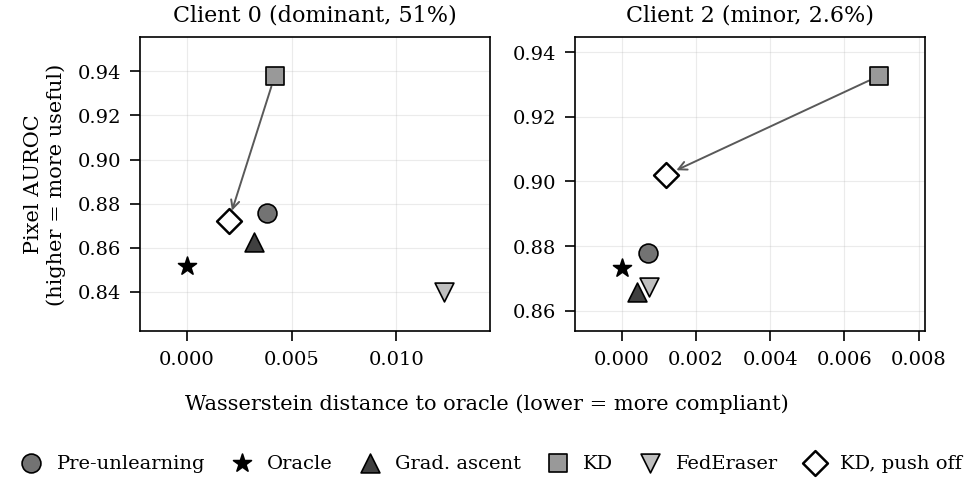

fig2_auroc_both_regimes.pdf


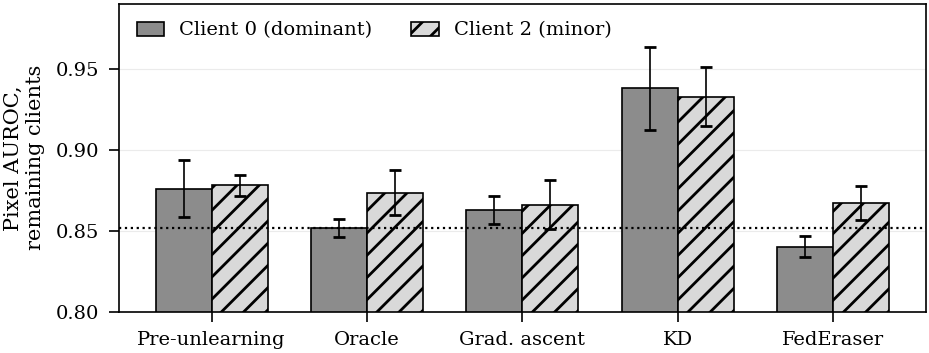

fig3_fidelity_divergence.pdf


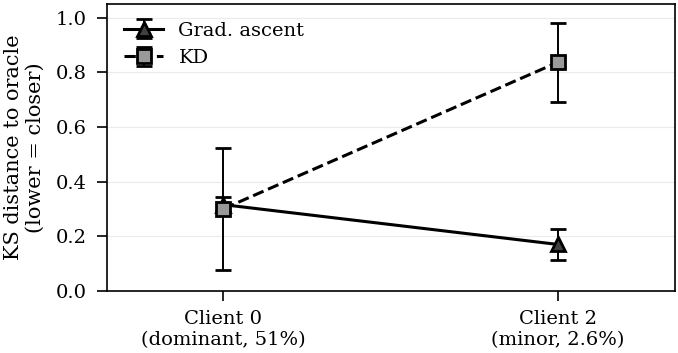

In [23]:
from IPython.display import display, Image

# make_paper_figures.py writes a PNG beside each PDF, so nothing external is needed.
figdir = Path(f"{CODE_LOCAL}/figures")
pngs = sorted(figdir.glob("*.png"))
for p in pngs:
    print(p.with_suffix(".pdf").name)
    display(Image(filename=str(p)))
if not pngs:
    print("No figures yet. Run the cell above.")

## 15. Save to Drive

Copies the harvested JSONs, environment record and figures to
`outputs_rewrite/reproduction/`.

In [24]:
DEST = f"{OUTPUTS_DRIVE}/reproduction"
Path(DEST).mkdir(parents=True, exist_ok=True)

n = 0
for p in sorted(Path(RESULTS_LOCAL).glob("*.json")):
    shutil.copy2(p, f"{DEST}/{p.name}"); n += 1
figdir = Path(f"{CODE_LOCAL}/figures")
if figdir.exists():
    Path(f"{DEST}/figures").mkdir(exist_ok=True)
    for p in sorted(figdir.glob("*.pdf")):
        shutil.copy2(p, f"{DEST}/figures/{p.name}"); n += 1

print(f"{n} files copied to {DEST}")
for p in sorted(Path(DEST).rglob("*")):
    if p.is_file():
        print(" ", str(p).replace(DEST + "/", ""), human(p.stat().st_size))

11 files copied to /content/drive/MyDrive/fed-unlearn-project/outputs_rewrite/reproduction
  environment.json 402 B
  figures/fig1_utility_vs_fidelity.pdf 17 KB
  figures/fig2_auroc_both_regimes.pdf 13 KB
  figures/fig3_fidelity_divergence.pdf 12 KB
  provenance.json 176 B
  results_seed123_forget0.json 360 KB
  results_seed123_forget2.json 20 KB
  results_seed2024_forget0.json 361 KB
  results_seed2024_forget2.json 20 KB
  results_seed42_forget0.json 630 KB
  results_seed42_forget2.json 20 KB


## Notes

**Determinism.** Per-worker dataloader shuffling was unseeded in the published
runs, so they are statistically but not bitwise reproducible. The variation was
measured: two configurations resolving to the same mathematics differ by 0.0007
in W1, and effect sizes are reported against that floor.
`federated/seeding.py` supports `experiment.deterministic: true`, which will
not match the paper exactly because the paper's runs predate it.

**Seed 42, client 0.** That archive was lost to corruption. Its oracle survives
as `oracle_seed42_forgot0.zip`, so section 11 restores the oracle and retrains
only the base federation.

**Table 2.** The push-weight ablation sets `alpha_push: 0.0` and reruns to a
separate `output_dir`. It is not part of the grid above.